# Fv/Fm extraction from a Walz Imaging-PAM leaf-disc array with fvfmPy

Reproduction of the core extraction workflow from:
**Garen, Arnold & Crous (2026), *User-friendly software for high-throughput processing of chlorophyll fluorescence images to assess plant stress responses: fvfmPy and fvfmR packages*, bioRxiv 2026.10.06.757212** (v1, posted 2026-10-09, DOI 10.64898/2026.10.06.757212).

- **Scientific scope (partial demonstration):** one bundled example image, `example1.pim` — a full 5×9 tray of leaf discs. The authors' pinned code segments the tray automatically with default settings, then computes Fo, Fm and **Fv/Fm = (Fm − Fo) / Fm** per disc (45 measurements expected).
- **Execution status:** executed in Colab on **CPU** (this method is classical computer vision; no GPU is used or needed).
- **Provenance:** the five analysis modules are the authors' **verbatim** code from `github.com/garenj/fvfmPy` commit `90d18231568121555f54b11b391af937d137c3f3`; the sample image is the authors' `inst/extdata/example1.pim` from `github.com/garenj/fvfmR` commit `3238b543286ce82064a0c6a21413a16d84aa0ce2`. Both are verified against pinned git blob hashes after download.
- **AI-assisted adaptation notice / AI支援に関する明示:** The authors' `fvfmPy/__init__.py` imports their PySide6 desktop GUI, which cannot run headless in Colab. This notebook therefore assembles a GUI-free package from the authors' five analysis modules (copied byte-for-byte from the pinned commit); **only the package `__init__.py` is AI-added glue** (it contains no analysis code) plus a one-line runtime compatibility shim for a scikit-image API mismatch in the authors' pinned code (documented below). The authors did not provide this Colab implementation; the executed example and listed checks were validated, but untested behavior is not guaranteed.
- **日本語:** このノートブックは、著者らの fvfmPy/fvfmR のピン留めされたコード（検証済みハッシュ）と付属サンプル画像 `example1.pim`（5×9=45 枚の葉ディスク）を Colab 上で CPU のみで実行し、各ディスクの Fo・Fm・Fv/Fm を抽出します。GUI（PySide6）はヘッドレス環境で実行できないため、解析モジュール5本は著者コードの一字一句をそのまま使い、`__init__.py` のみ AI 追加の最小限の代替です。

## Runtime selection / ランタイム選択

**Select Runtime → Change runtime type → CPU** (the default). The pipeline is OpenCV/scikit-image image processing on a single 640×480 frame — GPU offers no benefit, so this notebook never requests one.

**Run all** end-to-end: expected total ≈ 1–3 minutes, ≈ 1 MB of downloads (5 small code files + one 0.6 MB image). No credentials, no Drive mount.

**日本語:** ランタイムは CPU のままで構いません（OpenCV/scikit-image の画像処理のみで GPU 不要）。すべて実行で約1〜3分、ダウンロードは約1 MB です。

In [ ]:
import importlib.util, subprocess, sys

# Colab preinstalls the scientific stack; install only anything missing.
REQUIRED = {"numpy": "numpy", "cv2": "opencv-python", "scipy": "scipy",
            "skimage": "scikit-image", "pandas": "pandas", "matplotlib": "matplotlib"}
missing = [pkg for mod, pkg in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Installing missing packages:", missing)
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing],
                   check=True, timeout=600)
import numpy, cv2, scipy, skimage, pandas, matplotlib
print("numpy", numpy.__version__, "| opencv", cv2.__version__, "| scipy", scipy.__version__)
print("scikit-image", skimage.__version__, "| pandas", pandas.__version__,
      "| matplotlib", matplotlib.__version__)

numpy 2.1.3 | opencv 5.0.0 | scipy 1.16.3
scikit-image 0.25.2 | pandas 2.2.3 | matplotlib 3.10.0


## Step 1 — fetch the authors' pinned analysis code

Download the five fvfmPy modules needed for the `.pim` workflow from the pinned commit `90d18231568121555f54b11b391af937d137c3f3` and verify each file's **git blob SHA-1 and byte size** against the author repository tree (pinned 2026-10-23). `analyze_ROIs.py` computes the per-ROI metrics; `get_candidate_rois.py` detects leaf-disc centroids and assigns rows/columns; `estimate_grid_dims.py` infers the tray grid; `load_pim_img.py` decodes the Walz `.pim` format; `apply_rotation.py` rotates frames.

**日本語:** 著者の fvfmPy コミット `90d1823…` から解析に必要な5モジュールを取得し、git blob SHA-1 とバイト数を検証します。

In [ ]:
import hashlib
import urllib.request
from pathlib import Path

FVFMPY_COMMIT = "90d18231568121555f54b11b391af937d137c3f3"
RAW = f"https://raw.githubusercontent.com/garenj/fvfmPy/{FVFMPY_COMMIT}/src/fvfmPy"

# module -> (pinned git blob SHA-1, expected size in bytes)
MODULES = {
    "analyze_ROIs.py":       ("6348e9c11db8aa3ffefcec395a789f93b46bbba1", 3192),
    "get_candidate_rois.py": ("9cdf2f7e3f2ea92dfb5c4cc5f834b1fe39bcfd99", 6584),
    "estimate_grid_dims.py": ("e6e4bfd2373919702890bf91affee5d9b6549646", 4504),
    "load_pim_img.py":       ("a486c07675a523501323a408780556cbec166b13", 3431),
    "apply_rotation.py":     ("82e2eec1e60e26cd0917f3e1d22dc22044618235", 576),
}

pkg_dir = Path("/content/fvfmPy_authored/fvfmPy")
pkg_dir.mkdir(parents=True, exist_ok=True)
for name, (blob_sha, size) in MODULES.items():
    data = urllib.request.urlopen(f"{RAW}/{name}", timeout=60).read()
    got = (hashlib.sha1(b"blob %d\0" % len(data) + data).hexdigest(), len(data))
    assert got == (blob_sha, size), (name, got)
    (pkg_dir / name).write_bytes(data)
    print(f"verified {name}: {len(data)} bytes, git blob {got[0][:12]}...")

verified analyze_ROIs.py: 3192 bytes, git blob 6348e9c11db8...
verified get_candidate_rois.py: 6584 bytes, git blob 9cdf2f7e3f2e...
verified estimate_grid_dims.py: 4504 bytes, git blob e6e4bfd23739...
verified load_pim_img.py: 3431 bytes, git blob a486c07675a5...


verified apply_rotation.py: 576 bytes, git blob 82e2eec1e60e...


### GUI-free package glue (the only AI-added file)

The author package's `__init__.py` does `from .fvfmPy import run_fvfmPy`, which imports the PySide6 GUI — unusable headless. We substitute a minimal `__init__.py` containing only the author's version string, then import the five verbatim modules. **No analysis code is added or modified** (`__init__.py` を除き、解析コードは著者オリジナルのまま).

**One documented runtime compatibility fix / 互換性修正（1 件）:** the authors' pinned `get_candidate_rois.py` line 49 (commit `90d1823…`, also unchanged in the latest author commit `7aa30e05…`) calls `morphology.remove_small_objects(binary, max_size=MIN_AREA)`, but scikit-image's `remove_small_objects` only accepts `min_size` — the pinned call raises `TypeError` on every released scikit-image version. The author's own comment ("Filter out small objects/debris") and the `MIN_AREA` docstring ("minimum area of a leaf disc to keep") establish `min_size` semantics, so we translate the keyword at runtime. The downloaded author file itself stays byte-identical (git-blob-verified above).

In [ ]:
(pkg_dir / "__init__.py").write_text(
    '# FvFm processing code\n# Josef Garen, Pieter Arnold, and Kristine Crous\n'
    '# AI-added headless glue: author original imports the PySide6 GUI via fvfmPy.py.\n'
    '__version__ = "1.1.0"\n'
)
sys.path.insert(0, "/content/fvfmPy_authored")

from fvfmPy.analyze_ROIs import analyze_ROIs
from fvfmPy.apply_rotation import apply_rotation
from fvfmPy.estimate_grid_dims import estimate_grid_dims
from fvfmPy.get_candidate_rois import detect_centroids, assign_rois_to_grid
from fvfmPy.load_pim_img import load_pim, load_pim_grayscale

# AI-added scikit-image compatibility shim (see markdown above). The author file
# is untouched; we only translate the unsupported `max_size=` keyword to
# `min_size=` at call time, per the author's own MIN_AREA semantics.
import skimage.morphology as _skmorph

if not getattr(_skmorph.remove_small_objects, "_fvfm_compat", False):
    _orig_rso = _skmorph.remove_small_objects

    def _rso_compat(array, min_size=64, **kwargs):
        if "max_size" in kwargs:
            min_size = kwargs.pop("max_size")
        return _orig_rso(array, min_size=min_size, **kwargs)

    _rso_compat._fvfm_compat = True
    _skmorph.remove_small_objects = _rso_compat

print("fvfmPy pinned modules imported (GUI-free subset of commit", FVFMPY_COMMIT[:12] + ")")

fvfmPy pinned modules imported (GUI-free subset of commit 90d182315681)


## Step 2 — fetch the sample image (dataset bytes)

Download the authors' bundled example `example1.pim` (a full 5×9 tray) from `fvfmR` commit `3238b543286ce82064a0c6a21413a16d84aa0ce2`, verify its pinned git blob SHA-1 and size, then decode it with the authors' `load_pim()`: a zlib-compressed Walz `.pim` holding two 640×480 8-bit frames (frame 0 = Fo, frame 1 = Fm).

**日本語:** 付属サンプル `example1.pim`（fvfmR コミット `3238b54…`）をハッシュ検証付きで取得し、著者の `load_pim()` で解読します（Fo/Fm の2フレーム、640×480）。

In [ ]:
FVFMR_COMMIT = "3238b543286ce82064a0c6a21413a16d84aa0ce2"
PIM_URL = (f"https://raw.githubusercontent.com/garenj/fvfmR/"
           f"{FVFMR_COMMIT}/inst/extdata/example1.pim")
PIM_BLOB = "af22828242d998364a70e5be77e63c5234e4a50a"
PIM_SIZE = 618731

example1 = Path("/content/data/example1.pim")
example1.parent.mkdir(parents=True, exist_ok=True)
data = urllib.request.urlopen(PIM_URL, timeout=120).read()
got = (hashlib.sha1(b"blob %d\0" % len(data) + data).hexdigest(), len(data))
assert got == (PIM_BLOB, PIM_SIZE), got
example1.write_bytes(data)

frames = load_pim(str(example1))  # author decoder: zlib + TLV header, 2 frames
assert frames.shape == (2, 480, 640) and frames.dtype == numpy.uint8
print(f"example1.pim OK: {len(data)} bytes, git blob {got[0][:12]}...")
print(f"decoded {frames.shape[0]} frames of {frames.shape[1]}x{frames.shape[2]} uint8 (Fo, Fm)")

example1.pim OK: 618731 bytes, git blob af22828242d9...
decoded 2 frames of 480x640 uint8 (Fo, Fm)


## Step 3 — preview the input

Render both raw frames as grayscale. The tray should appear as bright leaf discs on dark cardstock. This is a direct view of the downloaded sample — no processing yet.

**日本語:** 生の2フレーム（Fo と Fm）をグレースケールで表示します。これは処理前の入力そのものです。

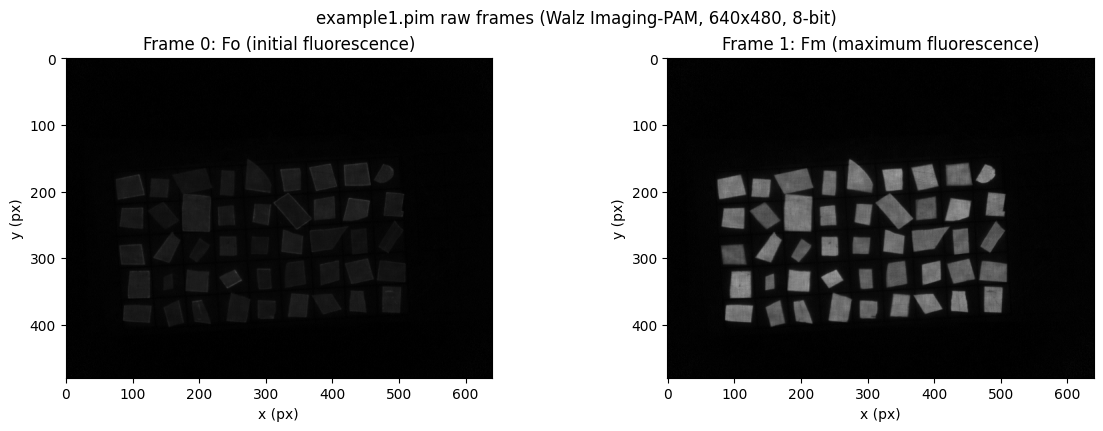

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)
axes[0].imshow(frames[0], cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Frame 0: Fo (initial fluorescence)")
axes[1].imshow(frames[1], cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Frame 1: Fm (maximum fluorescence)")
for ax in axes:
    ax.set_xlabel("x (px)"); ax.set_ylabel("y (px)")
fig.suptitle("example1.pim raw frames (Walz Imaging-PAM, 640x480, 8-bit)")
plt.show()

## Step 4 — automatic ROI detection and grid assignment (the paper's core step)

This replicates the authors' GUI default-parameter pipeline exactly (fvfmPy commit `90d1823…`, `fvfmPy.py::ImageViewer.load_image` with default sliders): `load_pim_grayscale` scales the Fo frame to 8-bit; `detect_centroids` applies Gaussian blur (kernel 3), adaptive threshold (neighbourhood 101, offset 2), small-object removal (min area 100), distance-transform + watershed separation (min distance 32) and a darkness filter; `estimate_grid_dims` infers the tray shape by PCA + gap analysis; `assign_rois_to_grid` assigns row/column. The authors document that **defaults detect all 45 ROIs and the correct 5×9 grid** for this image — asserted below.

**日本語:** 著者 GUI の既定パラメータ（blur 3 / 適応閾値101・オフセット2 / 最小面積100 / watershed 32）によるセグメンテーション→グリッド推定→行・列割り当てをそのまま実行します。著者ドキュメント通り 45 ROI・5×9 グリッドになることを検証します。

In [ ]:
# 8-bit Fo frame for detection (author function; analyze_ROIs uses the raw frames)
img = load_pim_grayscale(str(example1))

# Exact positional call made by ImageViewer.load_image with default sliders
centroid_dicts = detect_centroids(img, 10, 100, 3, 101, 32, 2)
print(f"detected {len(centroid_dicts)} candidate leaf-disc centroids")

est_rows, est_cols = estimate_grid_dims([(d["cx"], d["cy"]) for d in centroid_dicts])
roi_list = assign_rois_to_grid(img=None, centroid_dicts=centroid_dicts,
                               expected_rows=est_rows, expected_cols=est_cols,
                               ROI_SIZE=10, locked=True)
print(f"grid {est_rows} x {est_cols}; {len(roi_list)} ROIs assigned")

# Author-documented expectation for example1.pim (fvfmR README / fvfm_example docs)
assert (est_rows, est_cols) == (5, 9), f"expected 5x9 grid, got {est_rows}x{est_cols}"
assert len(roi_list) == 45, f"expected 45 ROIs, got {len(roi_list)}"
print("matches the authors' documented expectation: 45 ROIs on a 5x9 grid")

detected 45 candidate leaf-disc centroids
  [grid estimate] 45 centroids, span ratio 1.99 -> 5 rows x 9 cols (45 cells)
grid 5 x 9; 45 ROIs assigned
matches the authors' documented expectation: 45 ROIs on a 5x9 grid


### Detected ROIs overlaid on the input

Draw every assigned ROI (10×10 px square, as in the GUI's `add_point`) with its row,column label at the centroid, on the same Fo frame used for detection.

**日本語:** 検出された 45 個の ROI（10×10 px、GUI と同じスタイル）と行・列ラベルを入力画像に重ねて表示します。

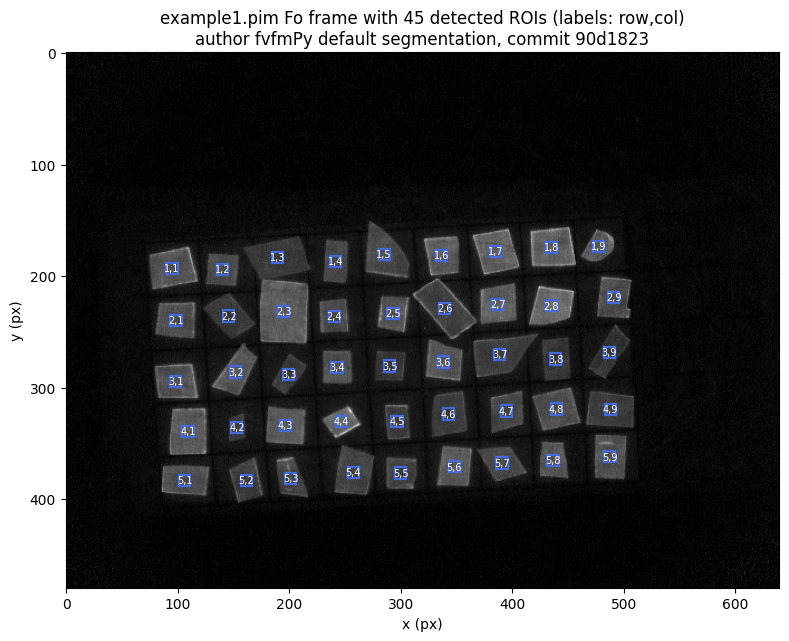

In [ ]:
fig, ax = plt.subplots(figsize=(9, 6.3), constrained_layout=True)
ax.imshow(img, cmap="gray", vmin=0, vmax=255)
for roi in roi_list:
    cx, cy = roi["centroid"]
    ax.add_patch(plt.Rectangle((cx - 5, cy - 5), 10, 10,
                               fill=False, edgecolor="royalblue", lw=1.6))
    ax.text(cx, cy, f"{roi['row']},{roi['col']}", color="white",
            fontsize=7, ha="center", va="center")
ax.set_title("example1.pim Fo frame with 45 detected ROIs (labels: row,col)\n"
             "author fvfmPy default segmentation, commit 90d1823")
ax.set_xlabel("x (px)"); ax.set_ylabel("y (px)")
plt.show()

## Step 5 — Fo, Fm and Fv/Fm extraction

Run the authors' `analyze_ROIs` — the exact call the GUI's **Analyze** button makes (`rotate_angle=0`, `crop_rect=None`): mean fluorescence of frames 0/1 inside each 10×10 ROI, `Fv/Fm = (Fm − Fo) / Fm` (guarded against Fm ≈ 0), results sorted by `leaf_number = (row−1)·n_cols + col`. Output columns match the `fvfmR::run_fvfm()` return/CSV contract; the CSV is written to `/content/fvfm_example1_results.csv`.

**日本語:** GUI の Analyze ボタンと同一の呼び出しで `analyze_ROIs` を実行し、各 ROI の Fo・Fm・Fv/Fm を抽出。出力列は `run_fvfm()` の CSV 仕様と同じで、`/content/fvfm_example1_results.csv` に保存されます。

In [ ]:
results = analyze_ROIs(str(example1), roi_list, 10, rotate_angle=0, crop_rect=None)
df = pandas.DataFrame(results)[
    ["filename", "row", "col", "leaf_number", "centroid_x", "centroid_y",
     "mean_Fo", "mean_Fm", "FvFm"]
]
assert len(df) == 45, f"expected 45 measurements, got {len(df)}"
df.to_csv("/content/fvfm_example1_results.csv", index=False)
print(f"{len(df)} measurements logged from {df['filename'].iloc[0]} -> /content/fvfm_example1_results.csv")
df

  [analyze ROIs] 45 measurements logged from file example1.pim
45 measurements logged from example1.pim -> /content/fvfm_example1_results.csv


,filename,row,col,leaf_number,centroid_x,centroid_y,mean_Fo,mean_Fm,FvFm
0,example1.pim,1,1,1,94.880848,193.001462,25.57,118.52,0.784256
1,example1.pim,1,2,2,139.982737,194.233046,23.99,119.33,0.798961
2,example1.pim,1,3,3,189.656067,183.148605,17.99,93.96,0.808536
3,example1.pim,1,4,4,241.575650,186.638298,21.98,107.50,0.795535
4,example1.pim,1,5,5,285.119542,180.546170,25.57,127.77,0.799875
5,example1.pim,1,6,6,336.849315,181.193738,29.40,137.83,0.786694
6,example1.pim,1,7,7,384.885360,177.924090,30.04,121.52,0.752798
7,example1.pim,1,8,8,435.451493,174.400000,29.19,105.64,0.723684
8,example1.pim,1,9,9,477.469355,173.438710,26.58,123.57,0.784899
9,example1.pim,2,1,10,98.475642,239.553587,23.51,109.46,0.785218


### Result summary and plausibility checks

Show descriptive statistics and verify the Fv/Fm values are finite and within (0, 1). Dark-adapted, non-stressed leaf discs typically give Fv/Fm ≈ 0.7–0.85; heat-stressed discs fall lower. This is a plausibility check for one example — **not** a validation of the paper's dataset-level results.

**日本語:** Fv/Fm の統計量と範囲（0–1、有限値）を確認します。健常な暗順応葉の Fv/Fm は 0.7–0.85 程度、熱ストレスを受けたディスクは低くなります。これは1枚のサンプルに対する妥当性確認であり、論文のデータセット全体の検証ではありません。

In [ ]:
stats = df[["mean_Fo", "mean_Fm", "FvFm"]].describe().round(4)
print(stats)

fv = df["FvFm"]
print(f"\nFv/Fm: min {fv.min():.3f}, mean {fv.mean():.3f}, max {fv.max():.3f}")
print("all finite:", bool(fv.notna().all()), "| all within (0,1):",
      bool(((fv > 0) & (fv < 1)).all()))

       mean_Fo   mean_Fm     FvFm
count  45.0000   45.0000  45.0000
mean   23.6904  108.7620   0.7820
std     4.6672   16.4147   0.0313
min    16.7100   80.0600   0.6506
25%    19.5600   95.7100   0.7702
50%    23.8200  109.4600   0.7902
75%    27.4200  121.5200   0.8025
max    34.3900  138.1800   0.8175

Fv/Fm: min 0.651, mean 0.782, max 0.817
all finite: True | all within (0,1): True


### Fv/Fm per tray position

Map Fv/Fm onto the 5×9 tray grid (rows/columns as assigned by the pipeline). This is an **additional visualization created for this notebook**, not an author figure. Per-disc values let you spot gradients or outliers (e.g. a stressed or damaged disc).

**日本語:** Fv/Fm を 5×9 のトレイ配置にマッピングします。これは本ノートブックで追加作成した可視化であり、著者の図ではありません。

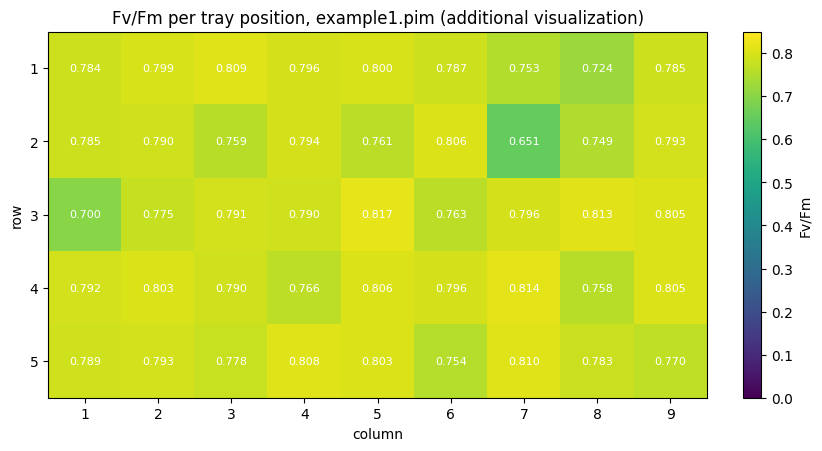

In [ ]:
grid = numpy.full((est_rows, est_cols), numpy.nan)
for rec in df.itertuples():
    grid[rec.row - 1, rec.col - 1] = rec.FvFm

fig, ax = plt.subplots(figsize=(8.6, 4.4), constrained_layout=True)
im = ax.imshow(grid, cmap="viridis", vmin=0.0, vmax=0.85)
for r in range(est_rows):
    for c in range(est_cols):
        ax.text(c, r, f"{grid[r, c]:.3f}", ha="center", va="center",
                color="white", fontsize=8)
ax.set_xticks(range(est_cols), [str(c + 1) for c in range(est_cols)])
ax.set_yticks(range(est_rows), [str(r + 1) for r in range(est_rows)])
ax.set_xlabel("column"); ax.set_ylabel("row")
ax.set_title("Fv/Fm per tray position, example1.pim (additional visualization)")
fig.colorbar(im, ax=ax, label="Fv/Fm")
plt.show()

## Interpretation, limitations, references

**What was reproduced.** The paper's core extraction workflow (its Section on image segmentation and automated ROI selection, and the fvfmPy/fvfmR software): automatic segmentation of a Walz `.pim` leaf-disc array with default settings and per-disc Fo/Fm/Fv-Fm extraction, verified to match the authors' documented expectation (45 ROIs, 5×9 grid).

**GUI-action → code mapping (fvfmPy commit `90d1823…`):**

| GUI action (fvfmR `run_fvfm` / fvfmPy window) | This notebook |
|---|---|
| open folder + load image | `load_pim_grayscale` + `load_pim` (Step 2) |
| default segmentation sliders | `detect_centroids(img, 10, 100, 3, 101, 32, 2)` (Step 4) |
| automatic rows/columns | `estimate_grid_dims` + `assign_rois_to_grid(locked=True)` (Step 4) |
| **Analyze** button (`analyze_image`) | `analyze_ROIs(..., rotate_angle=0, crop_rect=None)` (Step 5) |
| *Save results* | `df.to_csv(...)` — same columns as `run_fvfm()` |

Omitted GUI-only steps: interactive ROI editing, crop/rotate adjustments, re-analysis — the authors document these as unnecessary for `example1.pim`.

**Limitations / 未検証の範囲:**
- One bundled example image (45 measurements). This does **not** reproduce the paper's validation (40 images / 1799 measurements vs. manual ImagingWIN ROIs, r²>0.99) — that raw data is unpublished — nor the thermal-load-sensitivity example (`fvfmPy.figures`, de-identified species data, R modelling).
- The paper does not pin the fvfmPy version used for its reported validation; we use the current author commit.
- fvfmR is MIT-licensed; fvfmPy's `pyproject.toml` declares MIT, but no `LICENSE` file is present in the pinned tree (GitHub reports license: null). Author-declared MIT is recorded here.
- `leaf_number` ordering, Fm≈0 guard and column semantics follow `analyze_ROIs.py` verbatim; byte-level equality of the CSV against the paper's Table 1 description was not checked (flagged as unclear in the prior investigation).

**References:**
- Garen, Arnold & Crous (2026), bioRxiv 2026.10.06.757212 (v1).
- https://github.com/garenj/fvfmPy (commit `90d18231568121555f54b11b391af937d137c3f3`).
- https://github.com/garenj/fvfmR (commit `3238b543286ce82064a0c6a21413a16d84aa0ce2`), sample `inst/extdata/example1.pim`.

**日本語:** 本ノートブックは fvfmPy の核となる抽出処理（自動セグメンテーション→ Fo/Fm/Fv-Fm）を著者添付サンプル1枚で再現したものです。論文の検証実験（40画像・1799測定値）や熱耐性解析例は範囲外です。fvfmR は MIT、fvfmPy は pyproject で MIT 宣言（LICENSE ファイル自体はピン留めツリーに不在）。